# Titanic 생존 예측: Feature Engineering

891개 승객 데이터로 특성 공학 및 모델 성능 비교. 이 Notebook 하나에 원본 데이터와 전체 실험 코드가 포함되어 있다. Python 3 환경에서 아래 설치 셀을 필요시 실행한 뒤 Run All을 수행한다. 실행 시 `titanic_outputs` 폴더에 결과가 자동 생성된다. 기존 보고서와 동일한 실험 코드 및 데이터, seed=42를 사용한다.

## 0. 실행 환경
필요한 패키지가 설치되어 있지 않다면 다음 셀의 주석을 해제하여 설치하고 커널을 재시작한다.

In [ ]:
%pip install "numpy>=2.0,<3" "pandas>=2.0,<3" "matplotlib>=3.8,<4" "seaborn>=0.13,<1" "scikit-learn>=1.5,<2" "xgboost>=2,<4" "shap>=0.46,<1" "optuna>=4,<5"

## 1. 데이터 준비
[Kaggle Titanic](https://www.kaggle.com/competitions/titanic/data) / [CSV 공개 미러](https://github.com/agconti/kaggle-titanic/blob/master/data/train.csv). 원본 CSV를 압축 문자열로 포함해 별도 다운로드 없이 동일한 데이터를 사용한다.

In [ ]:
from pathlib import Path
import base64, gzip, hashlib
root = Path.cwd() / "titanic_outputs"
(root / "data").mkdir(parents=True, exist_ok=True)
# 원본 CSV (gzip + Base64)
encoded = (
    '...'
    'dI63iIN1XFHTydn58/8BKUIihArvAAA='
)
raw = gzip.decompress(base64.b64decode(encoded))
assert hashlib.sha256(raw).hexdigest() == '7d118fef8b6ccf7f81111877bc388536f7b1e498a655e3d649d19aaa010e9f6f'
(root / "data" / "train.csv").write_bytes(raw)
print("Dataset ready:", root / "data" / "train.csv")

## 2. 라이브러리 및 파생 변수 정의

In [ ]:
"""Titanic Feature Engineering assignment — reproducible end-to-end pipeline.

Usage: python run_all.py
Prerequisites: pip install -r requirements.txt
All fitted transformations and feature selections are inside sklearn Pipelines.
"""
from __future__ import annotations

import json
import re
import warnings
from dataclasses import asdict, dataclass
from pathlib import Path

import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shap
import optuna
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectFromModel
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score,
    precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder, OrdinalEncoder, RobustScaler, StandardScaler
from xgboost import XGBClassifier

ROOT = root
DATA = ROOT / 'data' / 'train.csv'
FIG = ROOT / 'figures'
RESULT = ROOT / 'results'
FIG.mkdir(exist_ok=True)
RESULT.mkdir(exist_ok=True)
SEED = 42
CV = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
NUM = ['Pclass', 'Age', 'SibSp', 'Parch', 'Fare']
CAT = ['Sex', 'Embarked']
BASE_NUM = ['Pclass', 'SibSp', 'Parch', 'Fare']
ENG_NUM = ['FamilySize', 'IsAlone', 'FarePerPerson', 'HasCabin']
ENG_CAT = ['Title', 'AgeGroup']

plt.rcParams.update({'font.family': 'DejaVu Sans', 'axes.unicode_minus': False,
                     'figure.dpi': 150, 'savefig.dpi': 170})
sns.set_theme(style='whitegrid', font='DejaVu Sans', rc={'axes.unicode_minus': False})
warnings.filterwarnings('ignore', message='X does not have valid feature names')
optuna.logging.set_verbosity(optuna.logging.WARNING)

@dataclass(frozen=True)
class Config:
    name: str
    imputation: str = 'median'
    encoding: str = 'onehot'
    scaling: str = 'standard'
    selection: bool = False
    engineering: bool = True
    base: bool = False


def engineering_features(frame: pd.DataFrame) -> pd.DataFrame:
    """Only row-local transformations, with no target information or fitted global statistics."""
    out = frame.copy()
    family = out['SibSp'] + out['Parch'] + 1
    out['FamilySize'] = family
    out['IsAlone'] = (family == 1).astype(int)
    out['FarePerPerson'] = out['Fare'] / family.clip(lower=1)
    out['HasCabin'] = out['Cabin'].notna().astype(int)
    title = out['Name'].str.extract(r',\s*([^.]*)\.', expand=False).str.strip()
    title = title.replace({'Mlle': 'Miss', 'Ms': 'Miss', 'Mme': 'Mrs'})
    out['Title'] = title.where(title.isin(['Mr', 'Mrs', 'Miss', 'Master']), 'Other')
    out['AgeGroup'] = pd.cut(out['Age'], bins=[-np.inf, 12, 18, 35, 60, np.inf],
                             labels=['Child', 'Teen', 'Young', 'Adult', 'Senior']).astype('object')
    return out

## 3. 전처리 파이프라인 및 평가 지표

In [ ]:
def build_pipeline(config: Config, model_name: str, model=None) -> Pipeline:
    if model is None:
        if model_name == 'LogisticRegression':
            model = LogisticRegression(max_iter=3000, random_state=SEED)
        elif model_name == 'RandomForest':
            model = RandomForestClassifier(n_estimators=90, min_samples_leaf=2,
                                           random_state=SEED, n_jobs=-1)
        elif model_name == 'XGBoost':
            model = XGBClassifier(n_estimators=180, max_depth=3, learning_rate=0.07,
                                  subsample=0.9, colsample_bytree=0.9,
                                  eval_metric='logloss', random_state=SEED, n_jobs=2)
        else:
            raise ValueError(model_name)
    if config.base:
        return Pipeline([('model', model)])

    number_cols = NUM + (ENG_NUM if config.engineering else [])
    cat_cols = CAT + (ENG_CAT if config.engineering else [])
    scaler = {'standard': StandardScaler(), 'minmax': MinMaxScaler(),
              'robust': RobustScaler(), 'none': 'passthrough'}[config.scaling]
    numeric = Pipeline([('imputer', SimpleImputer(strategy=config.imputation)),
                        ('scaler', scaler)])
    category_encoder = (OneHotEncoder(handle_unknown='ignore', sparse_output=False)
                        if config.encoding == 'onehot' else
                        OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1))
    categorical = Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                            ('encoder', category_encoder)])
    prep = ColumnTransformer([('num', numeric, number_cols),
                              ('cat', categorical, cat_cols)],
                             remainder='drop', verbose_feature_names_out=True)
    steps = [('prep', prep)]
    if config.selection:
        steps.append(('select', SelectFromModel(
            RandomForestClassifier(n_estimators=60, random_state=SEED, n_jobs=2),
            threshold=-np.inf, max_features=10)))
    steps.append(('model', model))
    return Pipeline(steps)


def conf_x(df: pd.DataFrame, cfg: Config) -> pd.DataFrame:
    if cfg.base:
        return df[BASE_NUM].copy()
    return engineering_features(df) if cfg.engineering else df.copy()


def calculate_metrics(model, x_test, y_test) -> dict:
    pred = model.predict(x_test)
    prob = model.predict_proba(x_test)[:, 1]
    return {"accuracy": accuracy_score(y_test, pred),
            "precision": precision_score(y_test, pred, zero_division=0),
            "recall": recall_score(y_test, pred, zero_division=0),
            "f1": f1_score(y_test, pred, zero_division=0),
            "roc_auc": roc_auc_score(y_test, prob),
            "train_f1": None}

## 4. EDA 및 그래프 생성

In [ ]:
def setup_eda(df):
    sns.set_theme(style='whitegrid', font='DejaVu Sans')
    miss = (df.isna().sum() / len(df) * 100).sort_values(ascending=False)
    pd.DataFrame({'column': miss.index, 'missing_n': df[miss.index].isna().sum().values,
                  'missing_pct': miss.values}).to_csv(RESULT / 'missing_values.csv', index=False)
    fig, ax = plt.subplots(figsize=(8.7, 4.6))
    colors = ['#167a8c' if i < 3 else '#cbd5e1' for i in range(len(miss))]
    ax.barh(miss.index[::-1], miss.values[::-1], color=colors[::-1])
    ax.set_xlim(0, 85); ax.set_xlabel('Missing rate (%)'); ax.set_title('Missing values by feature')
    for i, v in enumerate(miss.values[::-1]):
        if v > 0: ax.text(v+1, i, f'{v:.1f}%', va='center', fontsize=9)
    fig.tight_layout(); fig.savefig(FIG / '01_missing.png'); plt.close(fig)

    fig, axes = plt.subplots(1, 2, figsize=(10.2, 3.8))
    for val, name, color in [(0,'Not survived','#d26057'), (1,'Survived','#318a95')]:
        sns.histplot(data=df[df.Survived==val], x='Age', stat='density', bins=25,
                     element='step', fill=False, ax=axes[0], color=color, label=name)
    axes[0].legend(frameon=False); axes[0].set_title('Age distribution by survival')
    sns.histplot(data=df, x='Fare', bins=35, color='#318a95', ax=axes[1]);
    axes[1].set_title('Fare distribution (right-skewed)')
    fig.tight_layout(); fig.savefig(FIG / '02_histograms.png'); plt.close(fig)

    fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.8))
    sns.boxplot(data=df, x='Survived', y='Fare', color='#7dbfb9', ax=axes[0])
    axes[0].set_title('Fare boxplot by survival')
    sns.boxplot(data=df, x='Survived', y='Age', color='#b8acc9', ax=axes[1])
    axes[1].set_title('Age boxplot by survival')
    fig.tight_layout(); fig.savefig(FIG / '03_boxplots.png'); plt.close(fig)

    corr = df[['Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare']].corr()
    fig, ax = plt.subplots(figsize=(7.2, 5.7))
    sns.heatmap(corr, annot=True, fmt='.2f', vmin=-1, vmax=1,
                cmap='BrBG', center=0, square=True, ax=ax)
    ax.set_title('Pearson correlation (numeric features)')
    fig.tight_layout(); fig.savefig(FIG / '04_heatmap.png'); plt.close(fig)

    fig, axes = plt.subplots(1, 2, figsize=(9.2, 3.8))
    sns.countplot(data=df, x='Survived', ax=axes[0], color='#4f9ca5')
    axes[0].set_title('Target distribution'); axes[0].set_xticklabels(['0: No', '1: Yes'])
    sns.countplot(data=df, x='Sex', hue='Survived', ax=axes[1], palette=['#d26057','#318a95'])
    axes[1].set_title('Survival by sex'); axes[1].legend(title='Survived')
    fig.tight_layout(); fig.savefig(FIG / '05_barplots.png'); plt.close(fig)

    outlier = {}
    for col in ['Fare', 'Age']:
        q1, q3 = df[col].quantile([.25, .75]); iqr = q3-q1
        low, high = q1-1.5*iqr, q3+1.5*iqr
        outlier[col] = {'q1':float(q1),'q3':float(q3),'lower':float(low),
                        'upper':float(high),'outlier_count':int(((df[col]<low)|(df[col]>high)).sum())}
    return {'shape': list(df.shape), 'target_counts': {str(k):int(v) for k,v in df.Survived.value_counts().sort_index().items()},
            'target_rates':{str(k):float(v) for k,v in df.Survived.value_counts(normalize=True).sort_index().items()},
            'missing': {k: {'count':int(df[k].isna().sum()),'rate':float(df[k].isna().mean())} for k in df.columns},
            'outliers':outlier, 'correlation_with_target': {k: float(v) if pd.notna(v) else None for k,v in corr['Survived'].items()}}

## 5. 모델 평가 · 변수 중요도 · SHAP

In [ ]:
def evaluate(cfg, model_name, x_train_raw, y_train, x_test_raw, y_test, group, test=True):
    pipe = build_pipeline(cfg, model_name)
    xtr, xte = conf_x(x_train_raw, cfg), conf_x(x_test_raw, cfg)
    scores = cross_val_score(pipe, xtr, y_train, cv=CV, scoring='f1', n_jobs=1)
    pipe.fit(xtr, y_train)
    vals = calculate_metrics(pipe, xte, y_test)
    vals['train_f1'] = float(f1_score(y_train, pipe.predict(xtr)))
    row = {'group':group, 'experiment':cfg.name, 'model':model_name,
           'imputation': ('None' if cfg.base else cfg.imputation),
           'encoding':('None' if cfg.base else cfg.encoding),
           'scaling':('None' if cfg.base else cfg.scaling),
           'selection':cfg.selection, 'engineering':cfg.engineering,
           'cv_f1_mean':float(scores.mean()), 'cv_f1_std':float(scores.std()), **vals}
    return row, pipe


def save_importance(pipe, cfg, x_test, y_test):
    fitted_prep = pipe.named_steps['prep']
    features = fitted_prep.get_feature_names_out()
    if cfg.selection:
        mask = pipe.named_steps['select'].get_support()
        source_importance = pipe.named_steps['select'].estimator_.feature_importances_
        table = pd.DataFrame({'feature': features, 'selection_importance':source_importance,
                              'selected':mask})
        table.to_csv(RESULT/'selection_importance.csv', index=False)
        features = features[mask]
    importances = pipe.named_steps['model'].feature_importances_
    ranking = pd.DataFrame({'feature': features, 'importance':importances}).sort_values('importance', ascending=False)
    ranking.to_csv(RESULT/'tree_feature_importance.csv', index=False)
    top = ranking.head(12).iloc[::-1]
    fig, ax = plt.subplots(figsize=(9.0, 5.1))
    ax.barh(top['feature'].str.replace('num__','',regex=False).str.replace('cat__','',regex=False),
            top.importance, color='#2f7f91')
    ax.set_title('Tree-based feature importance (top 12)'); ax.set_xlabel('Importance (MDI)')
    fig.tight_layout(); fig.savefig(FIG/'06_feature_importance.png'); plt.close(fig)
    return ranking


def save_shap(rf_pipe, cfg, x_test_raw):
    """SHAP for a fitted RF model; positive class (survival) global importance."""
    sample = conf_x(x_test_raw, cfg).iloc[:min(120, len(x_test_raw))]
    transformed = rf_pipe.named_steps['prep'].transform(sample)
    names = rf_pipe.named_steps['prep'].get_feature_names_out()
    if cfg.selection:
        transformed = rf_pipe.named_steps['select'].transform(transformed)
        names = names[rf_pipe.named_steps['select'].get_support()]
    # TreeExplainer in SHAP 0.50: binary classifiers return (n,features,2)
    explainer = shap.TreeExplainer(rf_pipe.named_steps['model'])
    vals = explainer.shap_values(transformed)
    if isinstance(vals, list):
        positive = np.asarray(vals[1])
    else:
        vals = np.asarray(vals)
        positive = vals[:, :, 1] if vals.ndim == 3 else vals
    imp = np.abs(positive).mean(axis=0)
    order = np.argsort(imp)[::-1]
    shap_table = pd.DataFrame({'feature':np.asarray(names)[order], 'mean_abs_shap':imp[order]})
    shap_table.to_csv(RESULT/'shap_importance.csv', index=False)
    top = shap_table.head(12).iloc[::-1]
    fig, ax = plt.subplots(figsize=(9, 4.8))
    ax.barh(top.feature.str.replace('num__','',regex=False).str.replace('cat__','',regex=False),
            top.mean_abs_shap, color='#635a98')
    ax.set_title('SHAP mean absolute contribution (survival class)')
    ax.set_xlabel('Mean |SHAP value| (probability scale)')
    fig.tight_layout(); fig.savefig(FIG/'07_shap.png'); plt.close(fig)
    return shap_table


def plot_roc(models, x_test_raw, y_test):
    fig, ax = plt.subplots(figsize=(7.5,5.5))
    for label, (model, cfg) in models.items():
        yprob = model.predict_proba(conf_x(x_test_raw, cfg))[:,1]
        fpr, tpr, _ = roc_curve(y_test, yprob)
        auc = roc_auc_score(y_test, yprob)
        ax.plot(fpr,tpr,label=f'{label} (AUC={auc:.3f})',lw=2)
    ax.plot([0,1],[0,1],ls='--',color='gray',label='Random (AUC=0.500)')
    ax.set(title='ROC curves on held-out test set',xlabel='False positive rate',ylabel='True positive rate')
    ax.legend(loc='lower right',fontsize=9)
    fig.tight_layout(); fig.savefig(FIG/'08_roc.png'); plt.close(fig)


def plot_ablation(results):
    df = pd.DataFrame(results)
    fig, axes = plt.subplots(1, 2, figsize=(12.1,4.5))
    for ax, group, title in zip(axes, ['scaling','feature_selection'], ['Scaling comparison','Feature selection comparison']):
        d = df[df.group==group]
        sns.barplot(data=d, x='experiment',y='cv_f1_mean',hue='model', ax=ax, palette=['#468b99','#d29a54'])
        ax.set(title=title, xlabel='', ylabel='CV F1 score',ylim=(0.55,0.86))
        ax.tick_params(axis='x',labelrotation=20)
        ax.legend(fontsize=8)
    fig.tight_layout(); fig.savefig(FIG/'09_ablation.png'); plt.close(fig)

## 6. 전체 비교 실험 · GridSearchCV · Optuna

In [ ]:
def main():
    df = pd.read_csv(DATA)
    assert df.shape == (891,12), f'Unexpected dataset shape: {df.shape}'
    assert int(df.Survived.sum())==342
    summary = setup_eda(df)
    y = df['Survived'].astype(int)
    X = df.drop(columns='Survived')
    xtr, xte, ytr, yte = train_test_split(X,y,test_size=.20,random_state=SEED,stratify=y)
    summary['train_shape'] = list(xtr.shape)
    summary['test_shape'] = list(xte.shape)
    summary['split'] = {'test_size':.2,'stratify':'Survived','seed':SEED,
                        'cross_validation':'StratifiedKFold(3, shuffle=True, random_state=42)'}
    print(f'Dataset: {df.shape}; train: {xtr.shape}; test: {xte.shape}',flush=True)
    results = []
    main_configs = [Config(name='Base',base=True,engineering=False,scaling='none'),
        Config(name='Exp-1', imputation='mean',encoding='onehot',scaling='standard',selection=False),
        Config(name='Exp-2', imputation='median',encoding='ordinal',scaling='minmax',selection=True),
        Config(name='Exp-3', imputation='most_frequent',encoding='onehot',scaling='robust',selection=True)]
    main_models = {}
    for cfg in main_configs:
        for model in ['LogisticRegression','RandomForest']:
            row, pipe = evaluate(cfg,model,xtr,ytr,xte,yte,'main')
            results.append(row); main_models[(cfg.name,model)] = (pipe,cfg)
            print(cfg.name,model,'CV F1',round(row['cv_f1_mean'],4),'Test F1',round(row['f1'],4),flush=True)

    benchmark = Config('fixed',imputation='median',encoding='onehot',scaling='standard',engineering=True)
    ablation_configs = [
        ('imputation', Config('Mean',imputation='mean')),
        ('imputation', Config('Median',imputation='median')),
        ('imputation', Config('MostFrequent',imputation='most_frequent')),
        ('encoding', Config('OneHot',encoding='onehot')),
        ('encoding', Config('Ordinal',encoding='ordinal')),
        ('scaling', Config('None',scaling='none')),
        ('scaling', Config('Standard',scaling='standard')),
        ('scaling', Config('MinMax',scaling='minmax')),
        ('scaling', Config('Robust',scaling='robust')),
        ('engineering', Config('RawFeatures',engineering=False)),
        ('engineering', Config('EngineeredFeatures',engineering=True)),
        ('feature_selection', Config('AllFeatures',selection=False)),
        ('feature_selection', Config('Top10',selection=True))]
    ablation_models={}
    for group,cfg in ablation_configs:
        for model in ['LogisticRegression','RandomForest']:
            row,pipe = evaluate(cfg,model,xtr,ytr,xte,yte,group)
            results.append(row)
            ablation_models[(group,cfg.name,model)] = (pipe,cfg)
        print('Ablation completed:',group,cfg.name,flush=True)
    plot_ablation([r for r in results if r['group']!='main'])

    # Choose one preprocessing pipeline/model family by TRAIN-ONLY cross-validation.
    core = [r for r in results if r['group']=='main']
    chosen = max(core,key=lambda d:(d['cv_f1_mean'],-d['cv_f1_std']))
    cfg = next(c for c in main_configs if c.name==chosen['experiment'])
    model_choice = chosen['model']
    print('GridSearch input selected using training CV:',cfg.name,model_choice,flush=True)
    candidates = [('Main best (CV)', main_models[(cfg.name,model_choice)][0],cfg)]
    # GridSearchCV - operate only on training data, preprocessor/selector inside each fold.
    base_pipe = build_pipeline(cfg,model_choice)
    if model_choice=='RandomForest':
        grid = {'model__n_estimators':[90,150], 'model__max_depth':[5,None],
                'model__min_samples_leaf':[2]}
    else:
        grid = {'model__C':[.1,1.,3.,10.], 'model__class_weight':[None,'balanced']}
    grid_search = GridSearchCV(base_pipe,grid,scoring='f1',cv=CV,refit=True,n_jobs=1)
    grid_search.fit(conf_x(xtr,cfg),ytr)
    grid_scores = cross_val_score(clone(grid_search.best_estimator_),conf_x(xtr,cfg),ytr,cv=CV,scoring='f1')
    candidates.append(('GridSearchCV',grid_search.best_estimator_,cfg))
    print('GridSearch best:',grid_search.best_params_,'F1',grid_search.best_score_,flush=True)

    # AutoML-lite: Optuna automatically selects algorithm + hyperparameters, without peeking at test.
    auto_cfg = Config('AutoML',imputation='median',encoding='onehot',scaling='standard',engineering=True)
    auto_x = conf_x(xtr,auto_cfg)
    auto_cv = StratifiedKFold(n_splits=3,shuffle=True,random_state=SEED)
    def trial_pipeline(trial):
        family = trial.suggest_categorical('model_type',['LR','RF','XGB'])
        if family=='LR':
            mdl='LogisticRegression'
            params={'C':trial.suggest_float('lr_C',0.05,15,log=True),
                    'class_weight':trial.suggest_categorical('lr_class_weight',[None,'balanced'])}
            classifier=LogisticRegression(max_iter=3000,random_state=SEED,**params)
        elif family=='RF':
            mdl='RandomForest'
            classifier=RandomForestClassifier(
                n_estimators=trial.suggest_int('rf_trees',70,130,step=60),
                max_depth=trial.suggest_int('rf_depth',4,10,step=2),
                min_samples_leaf=trial.suggest_int('rf_min_leaf',1,4),
                n_jobs=2,random_state=SEED)
        else:
            mdl='XGBoost'
            classifier=XGBClassifier(
                n_estimators=trial.suggest_int('xgb_trees',70,130,step=60),
                max_depth=trial.suggest_int('xgb_depth',2,5),
                learning_rate=trial.suggest_float('xgb_lr',.03,.20,log=True),
                subsample=.9,colsample_bytree=.9,n_jobs=2,
                random_state=SEED,eval_metric='logloss')
        return build_pipeline(auto_cfg,mdl,classifier),mdl
    def objective(trial):
        pipe,_=trial_pipeline(trial)
        return float(cross_val_score(pipe,auto_x,ytr,cv=auto_cv,scoring='f1',n_jobs=1).mean())
    study=optuna.create_study(direction='maximize',sampler=optuna.samplers.TPESampler(seed=SEED))
    study.optimize(objective,n_trials=9,show_progress_bar=False)
    auto_model,auto_family=trial_pipeline(study.best_trial)
    auto_cv_scores=cross_val_score(auto_model,auto_x,ytr,cv=CV,scoring='f1')
    auto_model.fit(auto_x,ytr)
    candidates.append(('Optuna AutoML-lite',auto_model,auto_cfg))
    print('Optuna best',study.best_params,'3-fold',study.best_value,'3-fold',auto_cv_scores.mean(),flush=True)

    # Train-only CV used for final model choice (same 3-fold for all candidates).
    summary['candidate_cv']={
        'Main best (CV)':float(chosen['cv_f1_mean']),
        'GridSearchCV':float(grid_scores.mean()),
        'Optuna AutoML-lite':float(auto_cv_scores.mean())}
    best_label=max(summary['candidate_cv'],key=summary['candidate_cv'].get)
    best_pipeline,best_config=next((p,c) for n,p,c in candidates if n==best_label)
    summary['final_choice']={'label':best_label,'cv_f1':summary['candidate_cv'][best_label],
                             'config':asdict(best_config),
                             'model':type(best_pipeline.named_steps['model']).__name__}
    summary['grid_search']={'preprocessor':asdict(cfg),'base_model':model_choice,
                            'parameters':grid_search.best_params_, 'cv_best_f1':float(grid_search.best_score_)}
    summary['automl_lite']={'method':'Optuna TPESampler, 9 trials, 3-fold F1, LR/RF/XGBoost',
                            'best_parameters':study.best_params,
                            'best_model':auto_family,'search_cv_f1':float(study.best_value),
                            'comparison_3fold_f1':float(auto_cv_scores.mean())}

    tuned_rows=[]
    for label,model,cc in candidates:
        vals=calculate_metrics(model,conf_x(xte,cc),yte)
        vals['train_f1']=float(f1_score(ytr,model.predict(conf_x(xtr,cc))))
        tuned_rows.append({'candidate':label,'model':type(model.named_steps['model']).__name__,
                           'cv_f1':summary['candidate_cv'][label],**vals})
    pd.DataFrame(tuned_rows).to_csv(RESULT/'tuned_candidates.csv',index=False)
    summary['final_metrics']=next(r for r in tuned_rows if r['candidate']==best_label)

    # Explainability: RF with median/onehot/standard and top-10 feature selection.
    explain_cfg=Config('ExplainabilityRF',imputation='median',encoding='onehot',scaling='standard',selection=True)
    explain_rf=build_pipeline(explain_cfg,'RandomForest')
    explain_rf.fit(conf_x(xtr,explain_cfg),ytr)
    rf_rank=save_importance(explain_rf,explain_cfg,xte,yte)
    shap_rank=save_shap(explain_rf,explain_cfg,xte)
    summary['explainability_rf']={'test_f1':float(f1_score(yte,explain_rf.predict(conf_x(xte,explain_cfg)))),
                                  'selection_top10':pd.read_csv(RESULT/'selection_importance.csv').query('selected == True').sort_values('selection_importance',ascending=False)['feature'].tolist(),
                                  'shap_top5':shap_rank.head(5)['feature'].tolist()}
    show_roc={'Baseline RF':main_models[('Base','RandomForest')],
              'Exp-1 LR':main_models[('Exp-1','LogisticRegression')],
              'Final model':(best_pipeline,best_config)}
    plot_roc(show_roc,xte,yte)
    pred=best_pipeline.predict(conf_x(xte,best_config))
    cm=confusion_matrix(yte,pred)
    fig,ax=plt.subplots(figsize=(5.1,4.2))
    sns.heatmap(cm,annot=True,fmt='d',cmap='Blues',cbar=False,ax=ax)
    ax.set(xlabel='Predicted',ylabel='Actual',title='Final model confusion matrix')
    fig.tight_layout();fig.savefig(FIG/'10_confusion.png');plt.close(fig)
    summary['confusion_matrix']=cm.tolist()
    output=pd.DataFrame(results)
    output.to_csv(RESULT/'experiments.csv',index=False)
    pd.DataFrame([asdict(c) for c in main_configs]).to_csv(RESULT/'experiment_design.csv',index=False)
    with open(RESULT/'summary.json','w',encoding='utf8') as f:
        json.dump(summary,f,ensure_ascii=False,indent=2,default=str)
    print('Final:',summary['final_choice'],flush=True)
    print('Final test:',summary['final_metrics'],flush=True)
    print('All output files saved.',flush=True)

## 7. 전체 실험 실행
다음 셀을 실행하면 모든 분석과 결과 파일이 재생성된다.

In [ ]:
main()

## 8. 분석 결과 확인
아래 출력은 기존 동일 데이터 및 실험 코드의 실행 결과를 보존한 것이다. Run All을 수행하면 새 실행 결과로 갱신된다.

In [1]:
from pathlib import Path
import pandas as pd
import json
from IPython.display import display, Image, Markdown
data = pd.read_csv(root / 'data/train.csv')
results = pd.read_csv(root / 'results/experiments.csv', keep_default_na=False)
summary = json.loads((root / 'results/summary.json').read_text(encoding='utf-8'))
print('shape:', data.shape)
display(data.head())

shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 1. EDA: 결측치와 분포

원본 데이터를 직접 관찰한 뒤 전처리 요구사항을 검토한다.

,missing_count,missing_pct
Cabin,687,77.10
Age,177,19.87
Embarked,2,0.22


Target counts: {0: 549, 1: 342}


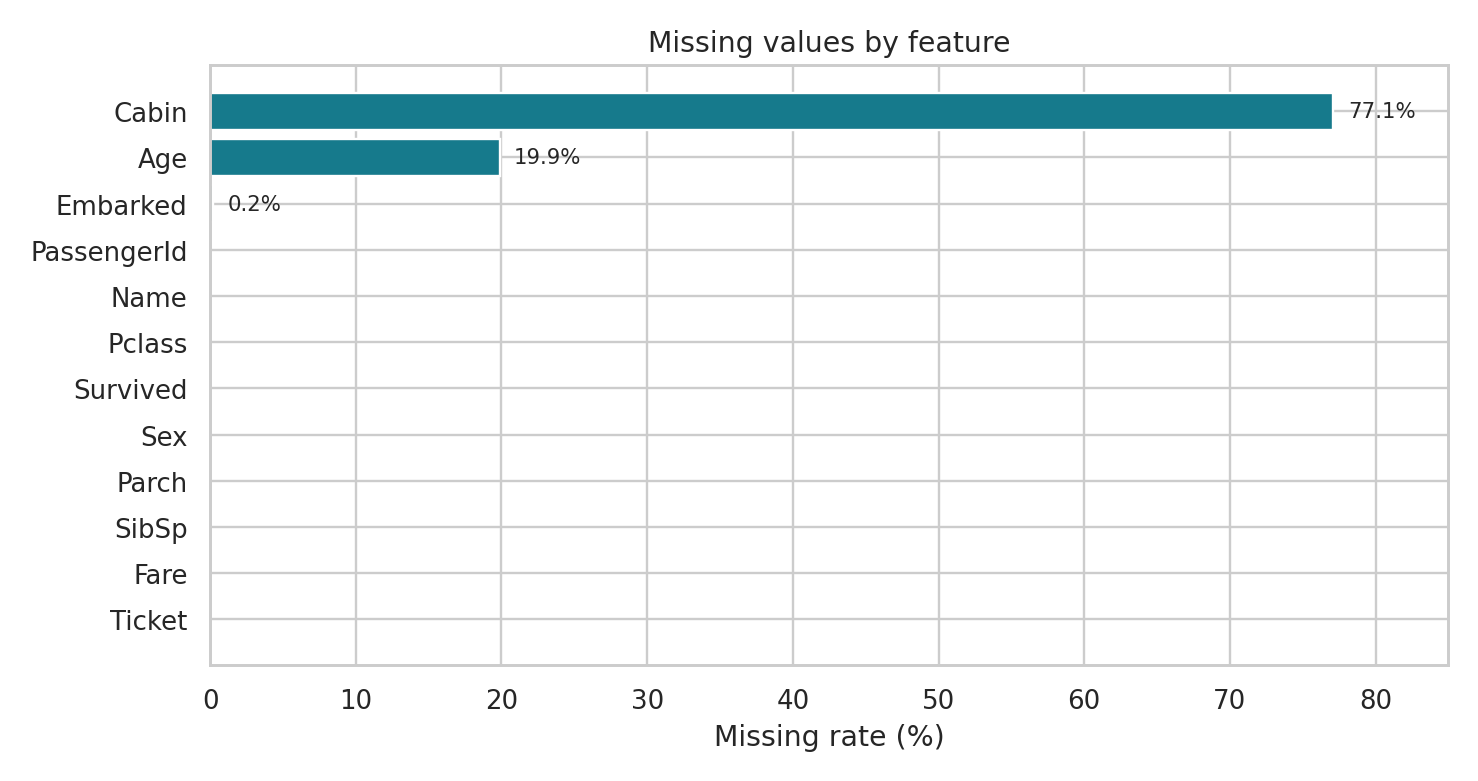

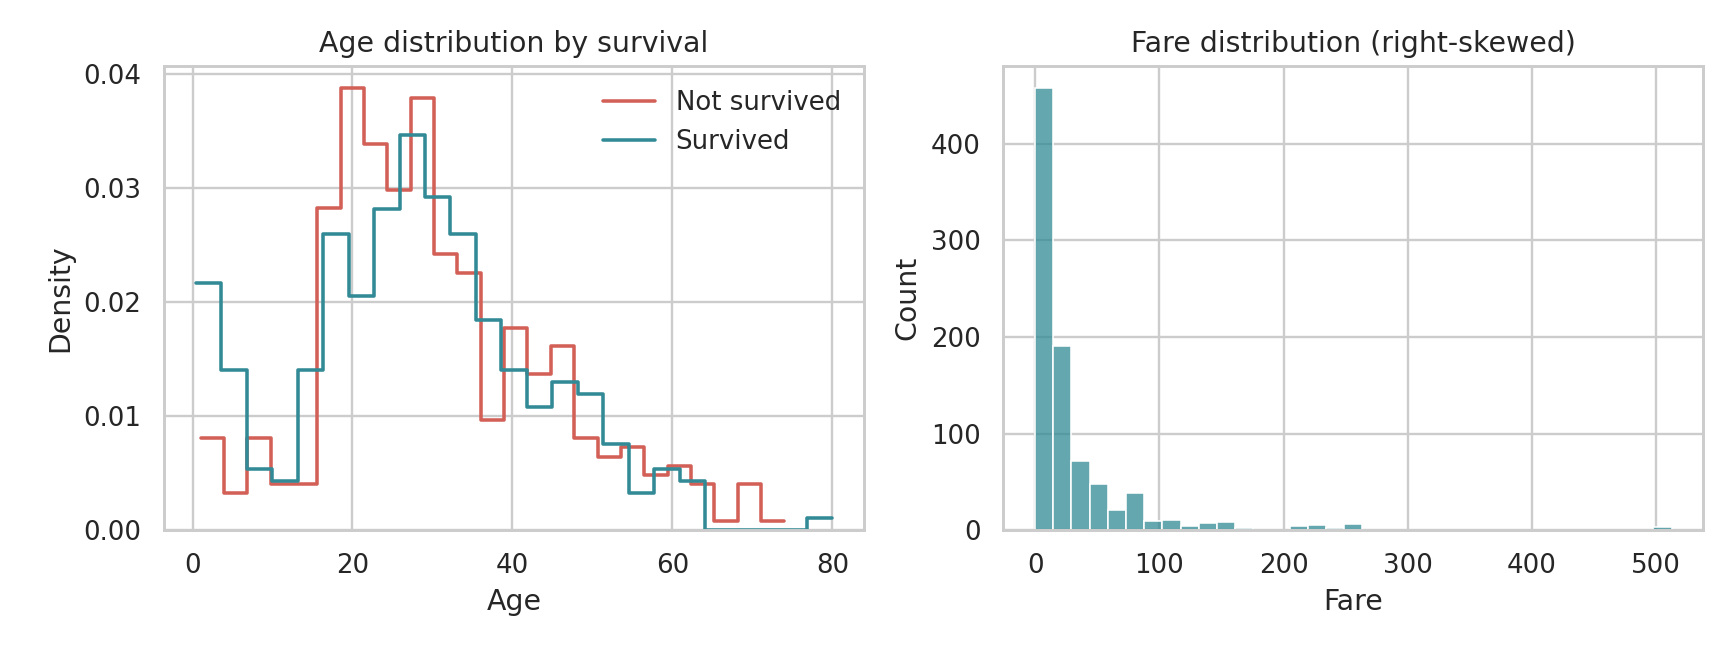

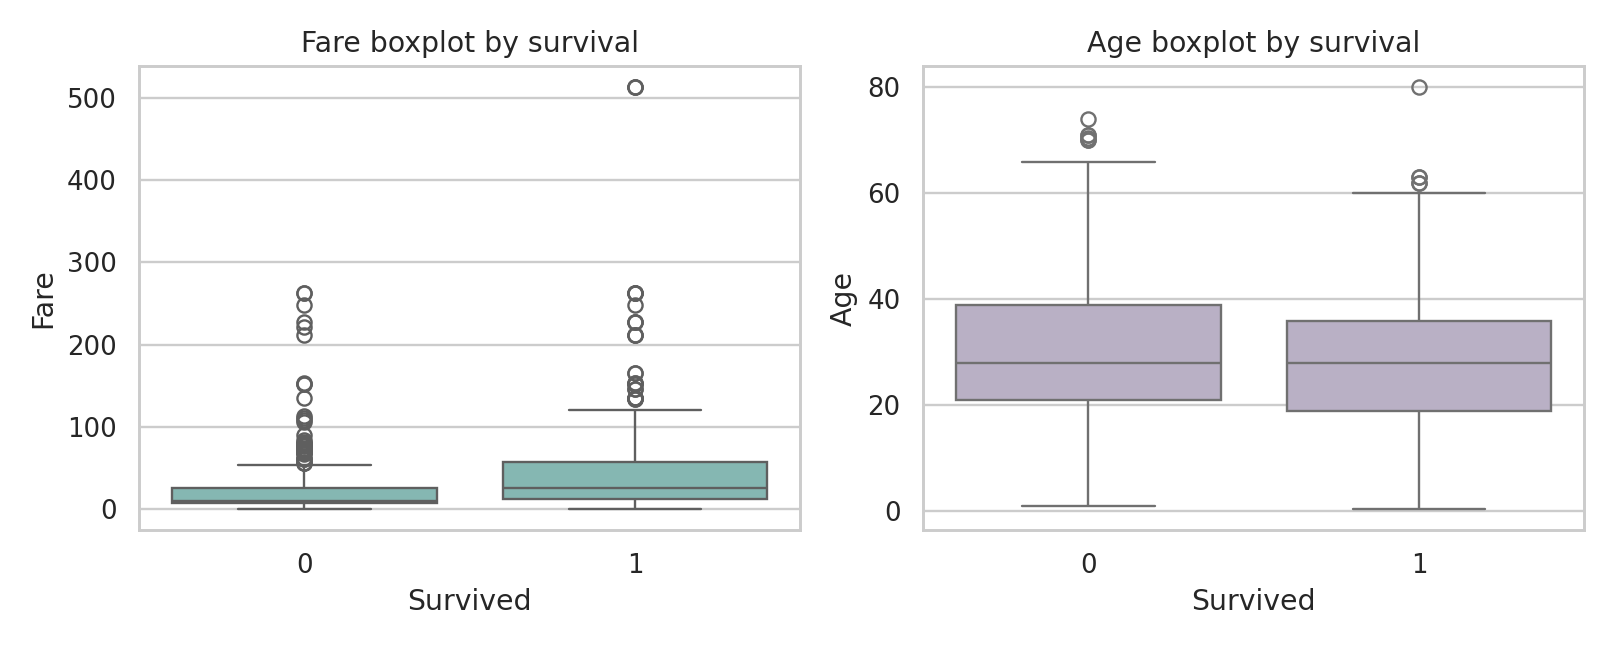

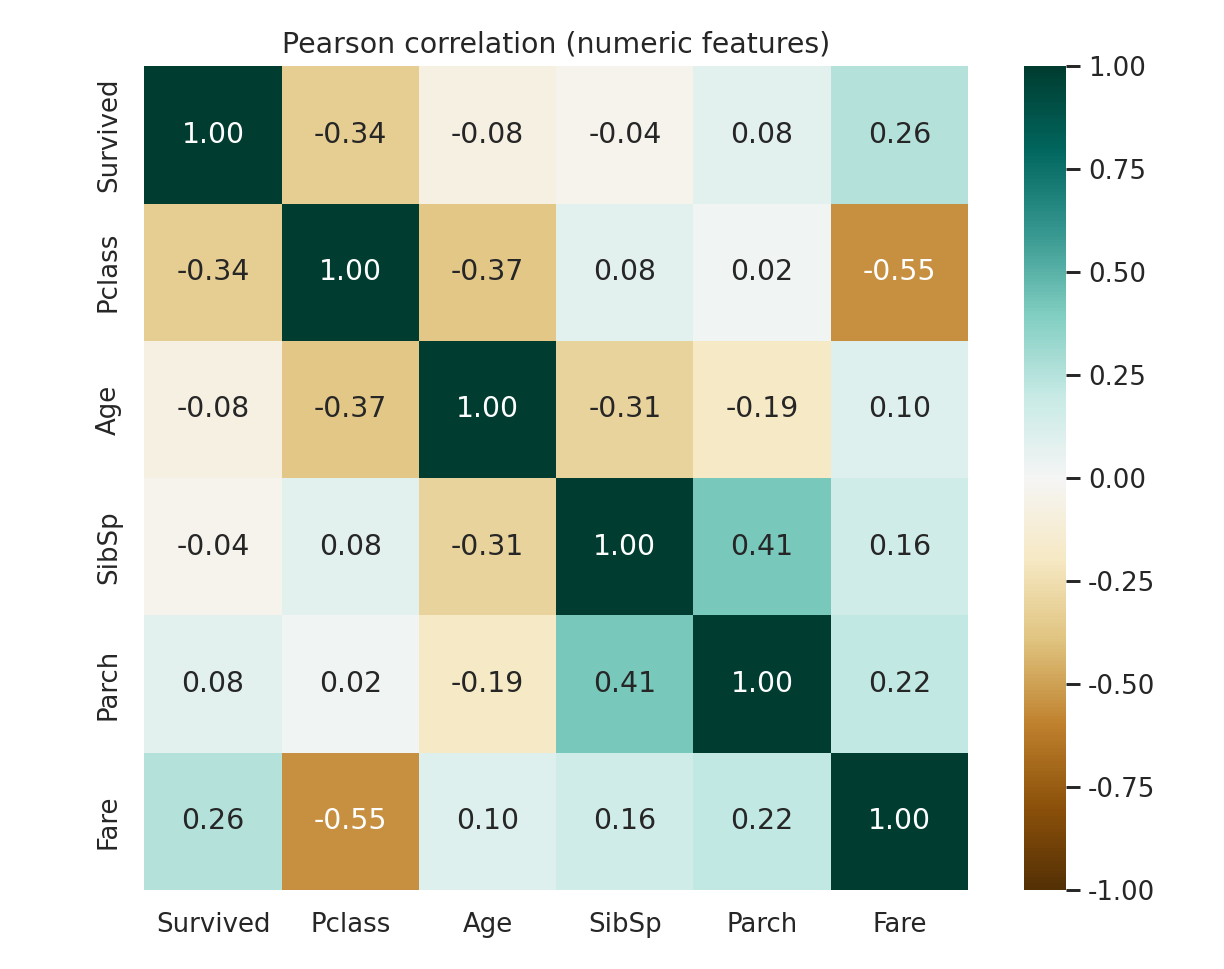

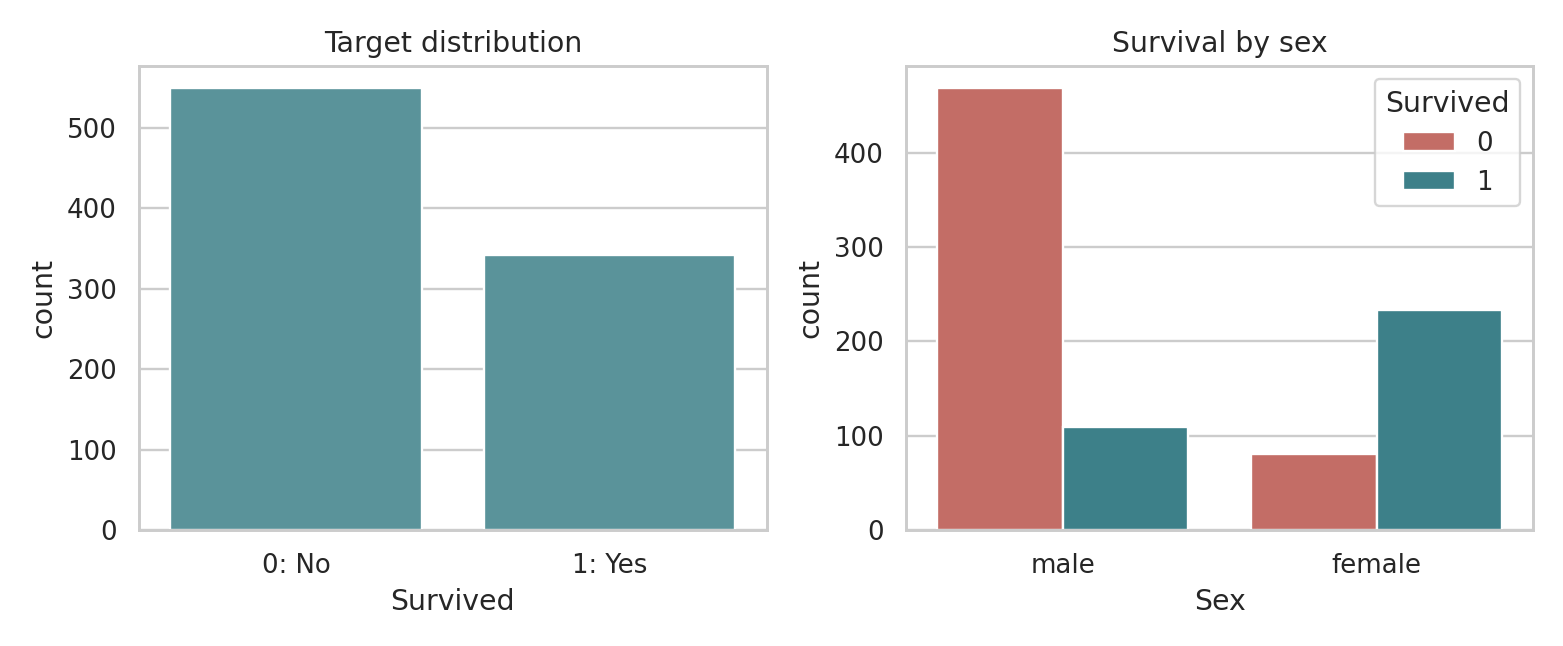

In [2]:
display(pd.DataFrame({'missing_count':data.isna().sum(), 'missing_pct':data.isna().mean()*100}).query('missing_count > 0').sort_values('missing_pct',ascending=False).round(2))
print('Target counts:',data.Survived.value_counts().sort_index().to_dict())
for filename in ['01_missing.png','02_histograms.png','03_boxplots.png','04_heatmap.png','05_barplots.png']:
    display(Image(filename=str(root / 'figures' / filename),width=650))

## 2. 파생 변수 생성

목표값을 사용하지 않는 승객별(row-local) 파생 변수를 만든다. 대치·인코딩·스케일링은 위에서 정의한 sklearn Pipeline이 각 학습 폴드 내부에서 처리한다.

In [3]:
engineered = engineering_features(data.drop(columns=['Survived']))
new_cols=['FamilySize','IsAlone','FarePerPerson','HasCabin','Title','AgeGroup']
display(engineered[new_cols].head(8))

/opt/pyvenv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,FamilySize,IsAlone,FarePerPerson,HasCabin,Title,AgeGroup
0,2,0,3.62500,0,Mr,Young
1,2,0,35.64165,1,Mrs,Adult
2,1,1,7.92500,0,Miss,Young
3,2,0,26.55000,1,Mrs,Young
4,1,1,8.05000,0,Mr,Young
5,1,1,8.45830,0,Mr,NaN
6,1,1,51.86250,1,Mr,Adult
7,5,0,4.21500,0,Master,Child


## 3. 필수 조합 실험: Base / Exp-1 / Exp-2 / Exp-3

교차검증은 훈련 데이터에서만 수행하고, 모든 모델에 동일한 홀드아웃 테스트 세트를 적용했다. Base는 전처리가 필요 없는 원시 수치형 4개만 사용한다.

In [4]:
cols=['experiment','model','imputation','encoding','scaling','selection','cv_f1_mean','accuracy','precision','recall','f1','roc_auc']
display(results.query('group == "main"')[cols].round(4))

,experiment,model,imputation,encoding,scaling,selection,cv_f1_mean,accuracy,precision,recall,f1,roc_auc
0,Base,LogisticRegression,None,None,None,False,0.5309,0.6480,0.5625,0.3913,0.4615,0.6742
1,Base,RandomForest,None,None,None,False,0.6205,0.6089,0.4932,0.5217,0.5070,0.6486
2,Exp-1,LogisticRegression,mean,onehot,standard,False,0.7626,0.8324,0.8000,0.7536,0.7761,0.8756
3,Exp-1,RandomForest,mean,onehot,standard,False,0.7675,0.8101,0.7692,0.7246,0.7463,0.8443
4,Exp-2,LogisticRegression,median,ordinal,minmax,True,0.7273,0.8101,0.7966,0.6812,0.7344,0.8502
5,Exp-2,RandomForest,median,ordinal,minmax,True,0.7745,0.8045,0.7742,0.6957,0.7328,0.8455
6,Exp-3,LogisticRegression,most_frequent,onehot,robust,True,0.7584,0.8212,0.7846,0.7391,0.7612,0.8593
7,Exp-3,RandomForest,most_frequent,onehot,robust,True,0.7750,0.7989,0.7538,0.7101,0.7313,0.8468


## 4. 독립 통제 실험

결측치 / 인코딩 / 스케일링 / 파생 변수 / 변수 선택을 각각 한 번에 한 요소만 바꾸어 비교한다.


 imputation


,experiment,model,cv_f1_mean,f1,roc_auc
8,Mean,LogisticRegression,0.7626,0.7761,0.8756
9,Mean,RandomForest,0.7675,0.7463,0.8443
10,Median,LogisticRegression,0.7626,0.7761,0.8751
11,Median,RandomForest,0.7633,0.7368,0.8449
12,MostFrequent,LogisticRegression,0.7624,0.7794,0.8734
13,MostFrequent,RandomForest,0.7700,0.7385,0.8480



 encoding


,experiment,model,cv_f1_mean,f1,roc_auc
14,OneHot,LogisticRegression,0.7626,0.7761,0.8751
15,OneHot,RandomForest,0.7633,0.7368,0.8449
16,Ordinal,LogisticRegression,0.7442,0.7273,0.8564
17,Ordinal,RandomForest,0.7587,0.7368,0.8408



 scaling


,experiment,model,cv_f1_mean,f1,roc_auc
18,None,LogisticRegression,0.7565,0.7761,0.8758
19,None,RandomForest,0.7633,0.7368,0.8455
20,Standard,LogisticRegression,0.7626,0.7761,0.8751
21,Standard,RandomForest,0.7633,0.7368,0.8449
22,MinMax,LogisticRegression,0.7684,0.7761,0.8717
23,MinMax,RandomForest,0.7610,0.7368,0.8455
24,Robust,LogisticRegression,0.7565,0.7761,0.8762
25,Robust,RandomForest,0.7633,0.7368,0.8451



 engineering


,experiment,model,cv_f1_mean,f1,roc_auc
26,RawFeatures,LogisticRegression,0.7216,0.7244,0.8437
27,RawFeatures,RandomForest,0.7576,0.7258,0.8433
28,EngineeredFeatures,LogisticRegression,0.7626,0.7761,0.8751
29,EngineeredFeatures,RandomForest,0.7633,0.7368,0.8449



 feature_selection


,experiment,model,cv_f1_mean,f1,roc_auc
30,AllFeatures,LogisticRegression,0.7626,0.7761,0.8751
31,AllFeatures,RandomForest,0.7633,0.7368,0.8449
32,Top10,LogisticRegression,0.7513,0.7556,0.8672
33,Top10,RandomForest,0.7730,0.7353,0.8507


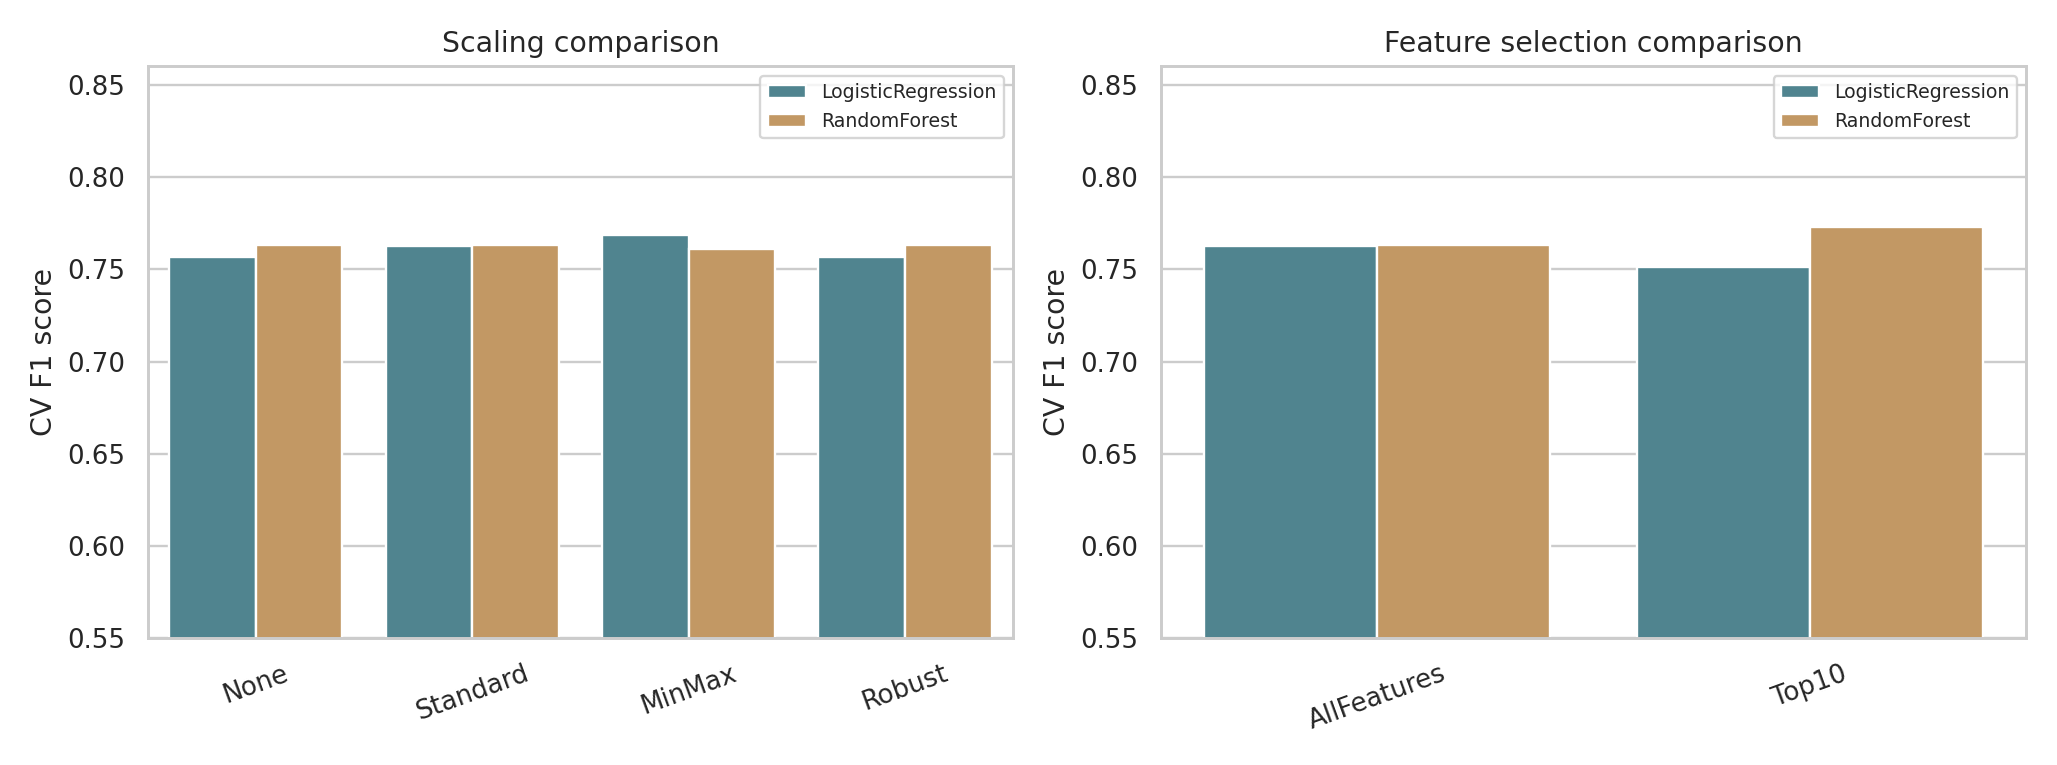

In [5]:
for group in ['imputation','encoding','scaling','engineering','feature_selection']:
    print('\n',group)
    display(results.loc[results.group.eq(group),['experiment','model','cv_f1_mean','f1','roc_auc']].round(4))
display(Image(filename=str(root / 'figures' / '09_ablation.png'),width=900))

## 5. 변수 선택 / SHAP 설명 가능성

RF 내장 중요도(MDI)와 SHAP 평균 절댓값을 보조적으로 사용했다. SHAP은 인과 관계를 증명하지 않는다.

,feature,selection_importance,selected
1,num__Age,0.145933,True
4,num__Fare,0.138670,True
7,num__FarePerPerson,0.134536,True
10,cat__Sex_male,0.099405,True
9,cat__Sex_female,0.078993,True
16,cat__Title_Mr,0.062651,True
0,num__Pclass,0.061592,True
5,num__FamilySize,0.038318,True
8,num__HasCabin,0.036331,True
15,cat__Title_Miss,0.030659,True


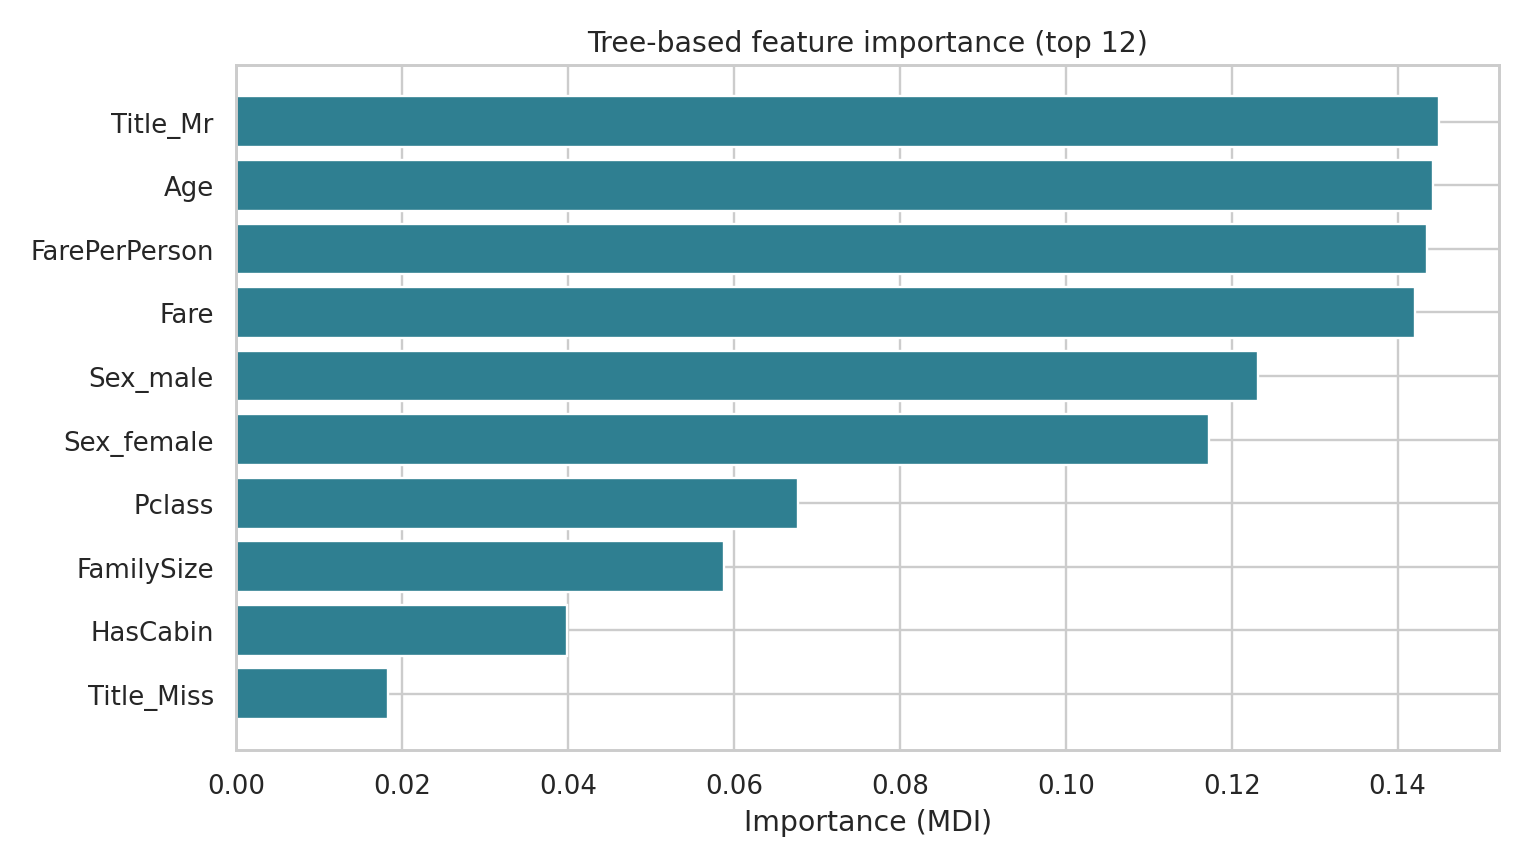

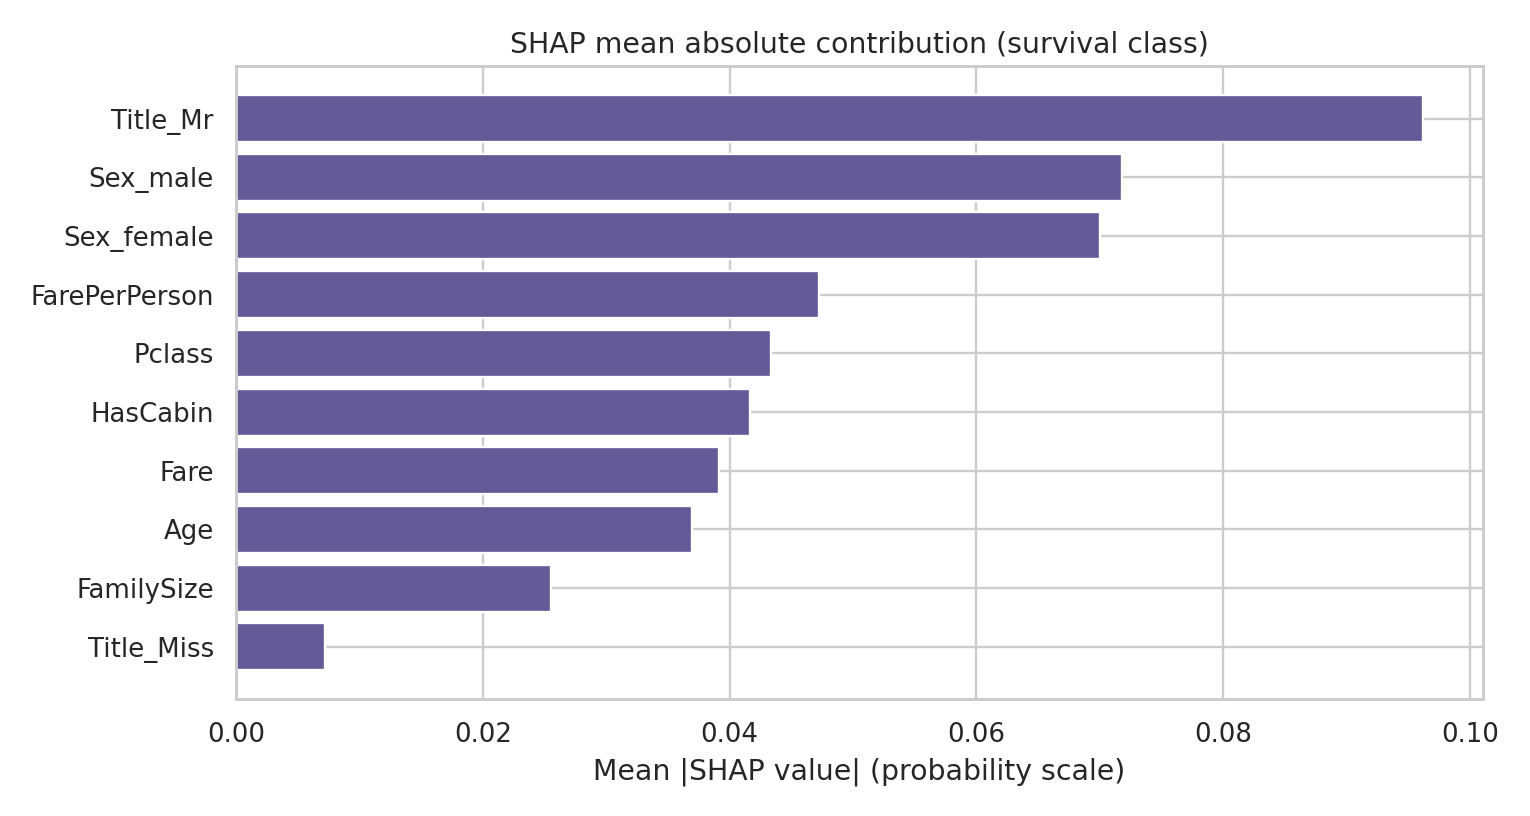

In [6]:
display(pd.read_csv(root/'results/selection_importance.csv').query('selected == True').sort_values('selection_importance',ascending=False))
for filename in ['06_feature_importance.png','07_shap.png']:
    display(Image(filename=str(root/'figures'/filename),width=750))

## 6. GridSearchCV, Optuna AutoML-lite, 최종 평가

Optuna는 LR/RF/XGBoost와 하이퍼파라미터를 자동으로 선택하는 제한된 AutoML-lite 실험이다.

,candidate,model,cv_f1,accuracy,precision,recall,f1,roc_auc,train_f1
0,Main best (CV),RandomForestClassifier,0.775,0.7989,0.7538,0.7101,0.7313,0.8468,0.8931
1,GridSearchCV,RandomForestClassifier,0.775,0.7989,0.7538,0.7101,0.7313,0.8468,0.8931
2,Optuna AutoML-lite,RandomForestClassifier,0.766,0.8101,0.7869,0.6957,0.7385,0.8565,0.7846


Final CV-selected model: {'label': 'Main best (CV)', 'cv_f1': 0.7749633354284517, 'config': {'name': 'Exp-3', 'imputation': 'most_frequent', 'encoding': 'onehot', 'scaling': 'robust', 'selection': True, 'engineering': True, 'base': False}, 'model': 'RandomForestClassifier'}
Final holdout test metrics: {'candidate': 'Main best (CV)', 'model': 'RandomForestClassifier', 'cv_f1': 0.7749633354284517, 'accuracy': 0.7988826815642458, 'precision': 0.7538461538461538, 'recall': 0.7101449275362319, 'f1': 0.7313432835820896, 'roc_auc': 0.846772068511199, 'train_f1': 0.8931297709923665}
Confusion matrix: [[94, 16], [20, 49]]


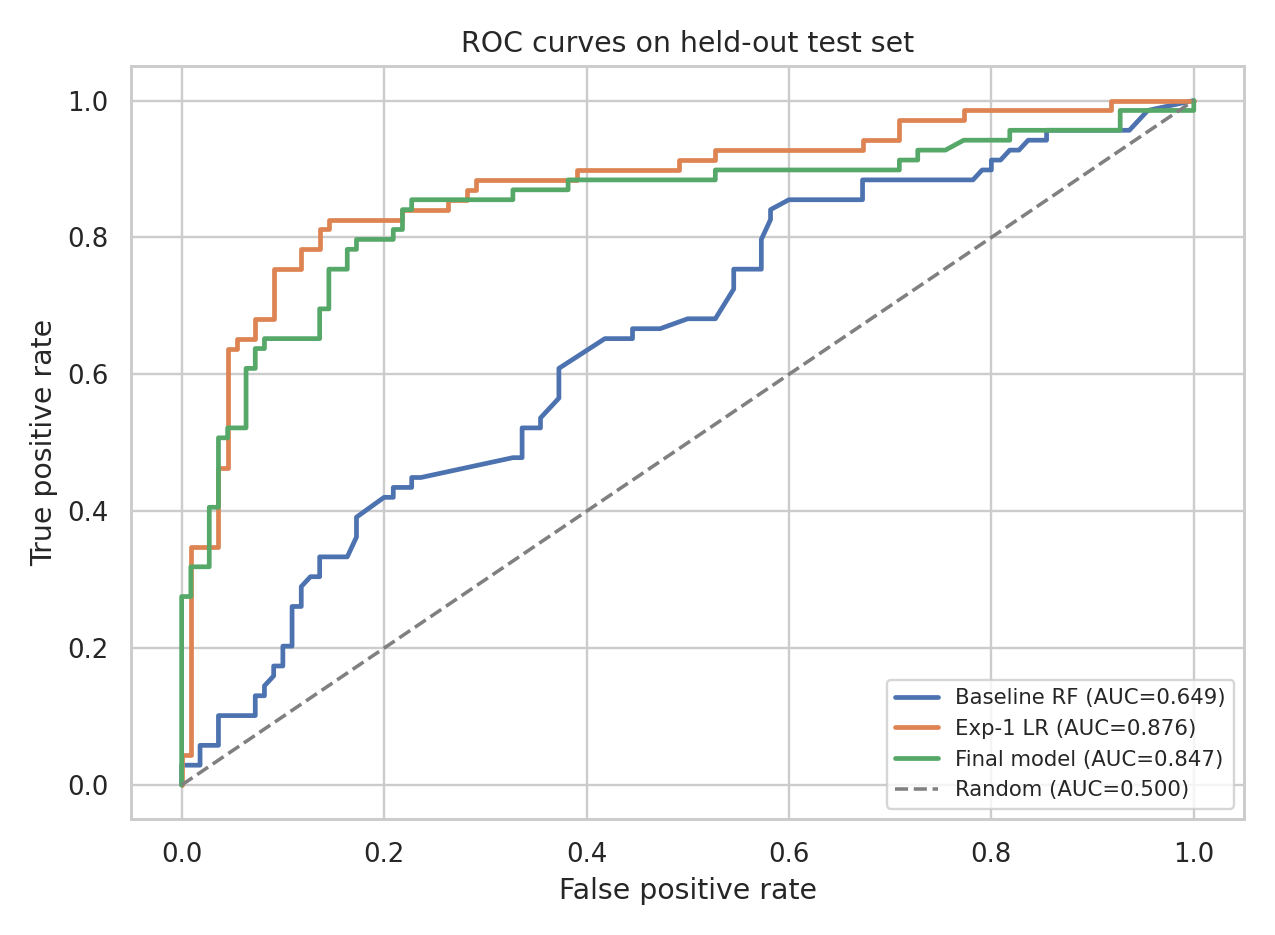

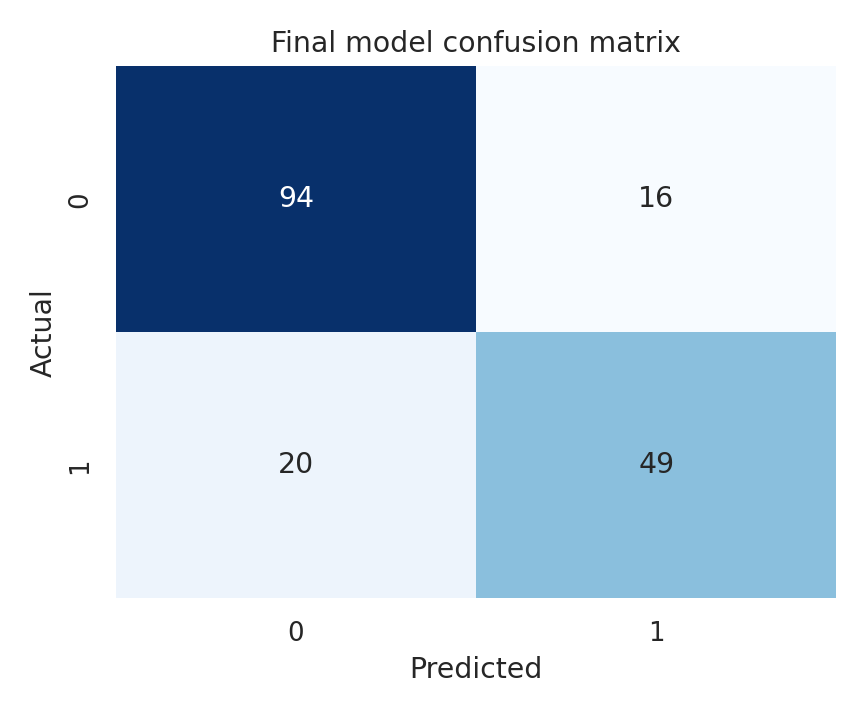

In [7]:
display(pd.read_csv(root/'results/tuned_candidates.csv').round(4))
print('Final CV-selected model:',summary['final_choice'])
print('Final holdout test metrics:', summary['final_metrics'])
print('Confusion matrix:',summary['confusion_matrix'])
for filename in ['08_roc.png','10_confusion.png']:
    display(Image(filename=str(root/'figures'/filename),width=670))

## 9. 재현성 및 한계
난수 시드는 42로 고정했다. 패키지 버전과 실행 환경에 따라 소수점 수준의 차이가 발생할 수 있다. Base는 결측치와 범주형 변수를 처리하지 않기 위해 원시 수치형 4개만 사용한다. Optuna 실험은 제한된 AutoML-lite 탐색이다. SHAP은 인과 관계를 증명하지 않는다.